In [77]:
from statistics import median
import warnings

import lightgbm
from numpy.ma.core import nomask
from statsmodels.sandbox.stats.multicomp import randmvn

warnings.simplefilter(action='ignore', category=FutureWarning)
import pandas as pd
from sklearn.model_selection import train_test_split, TimeSeriesSplit, RandomizedSearchCV

In [78]:
import plotly.express as px
from statsmodels.tsa.seasonal import seasonal_decompose

## In this project need to use LightGBM and Neural Nets (NN)

In [79]:
df = pd.read_csv(r'/Users/rr8/Documents/Food-Delivery-Duration-Prediction/dataset/historical_data.csv', parse_dates=['created_at','actual_delivery_time'])

## Data Cleaning

In [80]:
# remove the test order
df = df.query("created_at > '2014-10-20 00:00:00'")
df = df.sort_values('created_at')

In [81]:
# There are 7 undelivered orders, since the number of such rows is neglibible in this occasion I am excluding them from the dataset
mask = df['actual_delivery_time'].isna()
df = df[~mask]

In [82]:
# Fillna for missing values
# Categorical
df['store_primary_category'] = df['store_primary_category'].fillna('Unknown')
# Numeric (median)
df['total_busy_dashers'] = df['total_busy_dashers'].fillna(
    df['total_busy_dashers'].median()
)
df['total_items'] = df['total_items'].fillna(
    df['total_items'].median()
)
df['total_onshift_dashers'] = df['total_onshift_dashers'].fillna(
    df['total_onshift_dashers'].median()
)
df['estimated_store_to_consumer_driving_duration'] = df[
    'estimated_store_to_consumer_driving_duration'
].fillna(
    df['estimated_store_to_consumer_driving_duration'].median()
)
# Mode
df['market_id'] = df['market_id'].fillna(df['market_id'].mode()[0])
df['order_protocol'] = df['order_protocol'].fillna(df['order_protocol'].mode()[0])

In [83]:
import numpy as np
df['min_item_price'] = np.where(df['min_item_price']<0,0,df['min_item_price'])

median_subtotal = df['subtotal'].median()
df['subtotal'] = np.where(df['subtotal']==0, median_subtotal, df['subtotal'])

median_on_shift = df['total_onshift_dashers'].median()
df['total_onshift_dashers'] = np.where(df['total_onshift_dashers']<0, median_on_shift, df['total_onshift_dashers'])

median_busy_dr = df['total_busy_dashers'].median()
df['total_busy_dashers'] = np.where(df['total_busy_dashers']<0, median_busy_dr, df['total_busy_dashers'])

median_outs = df['total_outstanding_orders'].median()
df['total_outstanding_orders'] = np.where(df['total_outstanding_orders']<0, median_outs, df['total_outstanding_orders'])

median_est_driving = df['estimated_store_to_consumer_driving_duration'].median()
df['estimated_store_to_consumer_driving_duration'] = np.where(df['estimated_store_to_consumer_driving_duration']==0,median_est_driving,df['estimated_store_to_consumer_driving_duration'])

median_est_driving = df['estimated_order_place_duration'].median()
df['estimated_order_place_duration'] = np.where(df['estimated_order_place_duration']==0,median_est_driving,df['estimated_order_place_duration'])

In [84]:
df.describe()

,market_id,created_at,actual_delivery_time,store_id,order_protocol,total_items,subtotal,num_distinct_items,min_item_price,max_item_price,total_onshift_dashers,total_busy_dashers,total_outstanding_orders,estimated_order_place_duration,estimated_store_to_consumer_driving_duration
count,197420.000000,197420,197420,197420.000000,197420.00000,197420.000000,197420.000000,197420.000000,197420.000000,197420.000000,197420.000000,197420.000000,181159.000000,197420.000000,197420.000000
mean,2.973817,2015-02-04 22:00:42.659872,2015-02-04 22:48:27.791166,3530.581248,2.87288,3.196378,2684.326112,2.670788,686.221928,1159.588238,44.167967,41.105172,58.058611,308.679060,545.378948
min,1.000000,2015-01-21 15:22:03,2015-01-21 15:58:11,1.000000,1.00000,1.000000,12.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.000000,1.000000
25%,2.000000,2015-01-29 02:32:38.750000,2015-01-29 03:22:29.750000,1686.000000,1.00000,2.000000,1404.000000,1.000000,299.000000,800.000000,19.000000,17.000000,17.000000,251.000000,383.000000
50%,3.000000,2015-02-05 03:29:06.500000,2015-02-05 04:40:41.500000,3592.000000,3.00000,3.000000,2200.000000,2.000000,595.000000,1095.000000,37.000000,34.000000,41.000000,251.000000,544.000000
75%,4.000000,2015-02-12 01:39:15,2015-02-12 02:25:28,5299.000000,4.00000,4.000000,3395.000000,3.000000,949.000000,1395.000000,62.000000,59.000000,85.000000,446.000000,702.000000
max,6.000000,2015-02-18 06:00:44,2015-02-19 22:45:31,6987.000000,7.00000,411.000000,27100.000000,20.000000,14700.000000,14700.000000,171.000000,154.000000,285.000000,2715.000000,2088.000000
std,1.522625,NaN,NaN,2053.498629,1.50589,2.666554,1821.376308,1.630261,522.038742,558.416791,33.139698,30.863177,52.652173,89.896304,219.030972


In [85]:
df['delivery_duration_seconds'] = df['actual_delivery_time'] - df['created_at']
df['delivery_duration_seconds'] = df['delivery_duration_seconds'].dt.seconds

In [86]:
df.dtypes

market_id                                              float64
created_at                                      datetime64[us]
actual_delivery_time                            datetime64[us]
store_id                                                 int64
store_primary_category                                     str
order_protocol                                         float64
total_items                                              int64
subtotal                                               float64
num_distinct_items                                       int64
min_item_price                                           int64
max_item_price                                           int64
total_onshift_dashers                                  float64
total_busy_dashers                                     float64
total_outstanding_orders                               float64
estimated_order_place_duration                         float64
estimated_store_to_consumer_driving_duration           

In [87]:
df_time = df.set_index('created_at')
df_time = df_time.sort_index()

In [88]:
# Scan for outliers
print(df_time['delivery_duration_seconds'].sort_values(ascending=False).head(10))

created_at
2015-02-16 02:24:09    73282
2015-02-01 02:18:07    57032
2015-02-16 02:31:05    54447
2015-02-05 02:11:40    48178
2015-02-15 04:17:35    45685
2015-02-08 04:07:51    39352
2015-02-04 20:21:30    38457
2015-02-12 20:25:17    38143
2015-01-21 20:56:51    36196
2015-02-02 21:53:08    32929
Name: delivery_duration_seconds, dtype: int32


In [89]:
df_time['delivery_duration_seconds'].quantile(0.99)

np.float64(6473.809999999998)

In [90]:
from scipy.stats import mstats
# Winsorizing the data to the 1th and 99th percentiles
df_time['delivery_duration_seconds'] = mstats.winsorize(df_time['delivery_duration_seconds'], limits=[0.01, 0.01])

## 1h Decomposition

In [91]:
ts = df_time['delivery_duration_seconds'].resample('1h').mean()

In [92]:
from statsmodels.tsa.seasonal import seasonal_decompose
ts_filled = ts.interpolate(method='time')

In [93]:
decomp = seasonal_decompose(ts_filled, model='additive', period=24)

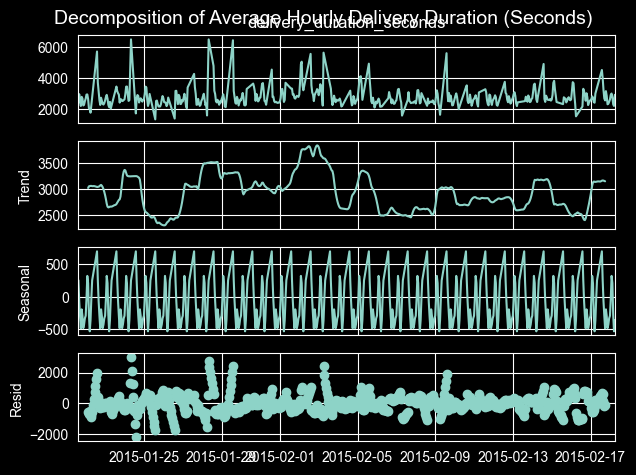

<Figure size 1500x1500 with 0 Axes>

In [94]:
# Plot the decomposed components
from matplotlib import pyplot as plt
decomp.plot()
plt.suptitle('Decomposition of Average Hourly Delivery Duration (Seconds)', fontsize=14)
plt.figure(figsize=(15,15))
plt.show()

## 1 DAY Decomposition

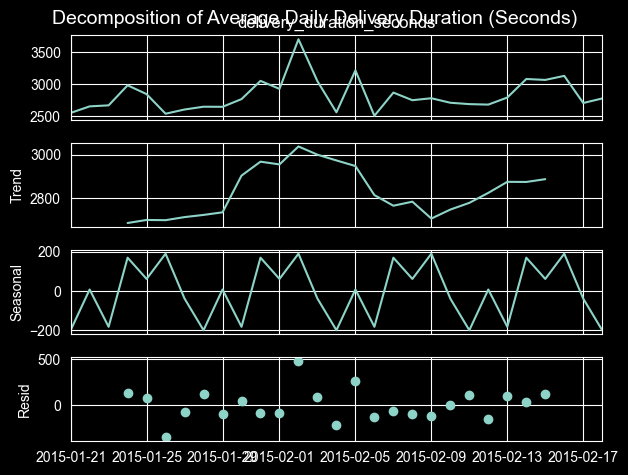

<Figure size 1500x1500 with 0 Axes>

In [95]:
ts_1 = df_time['delivery_duration_seconds'].resample('1D').mean()
ts_filled_1 = ts_1.interpolate(method='time')
decomp_1 = seasonal_decompose(ts_filled_1, model='additive', period=7)

# Plot the decomposed components
from matplotlib import pyplot as plt
decomp_1.plot()
plt.suptitle('Decomposition of Average Daily Delivery Duration (Seconds)', fontsize=14)
plt.figure(figsize=(15,15))
plt.tight_layout()
plt.show()

## PHASE 1: Feature Engineering

## Basket features

In [96]:
df['basket_complexity'] = df['num_distinct_items'] / df['total_items']

### Courier availability features

In [97]:
df['outstanding_order_load'] = np.where(
    df['total_onshift_dashers'] > 0,
    df['total_outstanding_orders'] / df['total_onshift_dashers'],
    0
)

df['dasher_busy_ratio'] = np.where(
    df['total_onshift_dashers'] > 0,
    df['total_busy_dashers'] / df['total_onshift_dashers'],
    0
)

df['dasher_busy_ratio'] = df['dasher_busy_ratio'].clip(upper=1.0)

In [98]:
df['net_available_dashers'] = df['total_onshift_dashers'] - df['total_busy_dashers']
df['net_available_dashers'] = df['net_available_dashers'].clip(lower=0)

## Time-Related Features

In [99]:
df['order_hour'] = df['created_at'].dt.hour
df['order_weekday'] = df['created_at'].dt.weekday
df['order_weekday_hour'] = df['order_weekday'].astype(str) + '_' + df['order_hour'].astype(str)
df['order_is_weekend'] = df['order_weekday'].isin([5,6]).astype(int)

## Estimated Features

In [100]:
df['estimated_order_total_seconds'] = df['estimated_order_place_duration'] + df['estimated_store_to_consumer_driving_duration']

In [101]:
df.isna().sum()

market_id                                           0
created_at                                          0
actual_delivery_time                                0
store_id                                            0
store_primary_category                              0
order_protocol                                      0
total_items                                         0
subtotal                                            0
num_distinct_items                                  0
min_item_price                                      0
max_item_price                                      0
total_onshift_dashers                               0
total_busy_dashers                                  0
total_outstanding_orders                        16261
estimated_order_place_duration                      0
estimated_store_to_consumer_driving_duration        0
delivery_duration_seconds                           0
basket_complexity                                   0
outstanding_order_load      

In [102]:
# Filling NA values for columns
df['total_outstanding_orders'] = df['total_outstanding_orders'].fillna(df['total_outstanding_orders'].median())

df['outstanding_order_load'] = df['outstanding_order_load'].fillna(df['outstanding_order_load'].median())

# PHASE 2: Neural Networks

## 2.1 Preparing data for Neuron Networks

#### Importing all packages

In [103]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.compose import ColumnTransformer
import tensorflow as tf
from tensorflow.keras import layers, Model
import numpy as np

In [104]:
# Sort by time to preserve temporal structure
df_nn = df.sort_values('created_at').reset_index(drop=True)

Splitting Features

In [105]:
target = 'delivery_duration_seconds'
cat_features = [
            'order_protocol',
            'store_primary_category',
            'order_weekday_hour',
            'order_is_weekend',
            'market_id'
]

num_features = [
    'total_items',
    'subtotal',
    'num_distinct_items',
    'min_item_price',
    'max_item_price',
    'total_onshift_dashers',
    'total_busy_dashers',
    'total_outstanding_orders',
    'estimated_order_place_duration',
    'estimated_store_to_consumer_driving_duration',
    'estimated_order_total_seconds',
    'basket_complexity',
    'outstanding_order_load',
    'dasher_busy_ratio',
    'net_available_dashers',
    'order_hour'
]

embedding_features = [
    'store_id'
]

##### Train Test split

In [106]:
# Train / Test split (time-based)

train_size = int(len(df_nn) * 0.8)
train_df = df_nn.iloc[:train_size].copy()
test_df = df_nn.iloc[train_size:].copy()


##### Embedding high cardinality feature (store_id)

In [107]:
label_encoders = {}

for col in embedding_features:
    le = LabelEncoder()

    train_df[col] = le.fit_transform(train_df[col].astype(str))
    test_df[col] = test_df[col].astype(str)

    test_df[col] = test_df[col].apply(
        lambda x: le.transform([x])[0] if x in le.classes_ else -1
    )

    label_encoders[col] = le

In [108]:
# shift so -1 becomes 0 for embedding
for col in embedding_features:
    train_df[col] = train_df[col] + 1
    test_df[col] = test_df[col] + 1

##### Tabular Preprocessing (StandardScaler, OneHotEncoder)

In [109]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_features),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_features),
    ],
    remainder='drop'
)

##### Fitting and Log-Transforming


In [110]:
X_train = train_df[num_features + cat_features]
X_test = test_df[num_features + cat_features]

# Log-transform the target for NN
y_train = np.log1p(train_df[target].values)
y_test = np.log1p(test_df[target].values)

X_train_transformed = preprocessor.fit_transform(X_train)
X_test_transformed = preprocessor.transform(X_test)

#### Embedding store_id separately

In [111]:
# Embedding input data
X_train_store = train_df['store_id'].astype('int32').values
X_test_store = test_df['store_id'].astype('int32').values

In [112]:
# Model inputs
store_input = layers.Input(shape=(1,), dtype='int32', name='store_id')
numeric_input = layers.Input(shape=(X_train_transformed.shape[1],), name='tabular')

In [113]:
# vocabulary size
store_vocab = len(label_encoders['store_id'].classes_) + 1

store_emb = layers.Embedding(
    input_dim=store_vocab,
    output_dim=16
)(store_input)

store_emb = layers.Flatten()(store_emb)

In [114]:
# Merge features
x = layers.Concatenate()([
    numeric_input,
    store_emb
])

In [115]:
# Dense network
x = layers.Dense(256, activation='relu')(x)
x = layers.Dropout(0.2)(x)
x = layers.Dense(128, activation='relu')(x)
x = layers.Dense(64, activation='relu')(x)

output = layers.Dense(1)(x)

model = Model(
    inputs=[numeric_input, store_input],
    outputs=output
)

In [116]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-3),
    loss=tf.keras.losses.Huber(),
    metrics=['mae']
)

model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ store_id            │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_1         │ (None, 1, 16)     │    105,040 │ store_id[0][0]    │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ tabular             │ (None, 230)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_1 (Flatten) │ (None, 16)        │          0 │ embedding_1[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_1       │ (None, 246)       │          0 │ tabular[0][0],    │
│ (Concatenate)       │                   │            │ flatten_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_4 (Dense)     │ (None, 256)       │     63,232 │ concatenate_1[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 256)       │          0 │ dense_4[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_5 (Dense)     │ (None, 128)       │     32,896 │ dropout_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_6 (Dense)     │ (None, 64)        │      8,256 │ dense_5[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_7 (Dense)     │ (None, 1)         │         65 │ dense_6[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 209,489 (818.32 KB)

 Trainable params: 209,489 (818.32 KB)

 Non-trainable params: 0 (0.00 B)

In [117]:
# Safety checks for embedding correctness
assert X_train_store.min() >= 0
assert X_train_store.max() < store_vocab
assert X_train_store.dtype == np.int32

In [118]:
# Train model
model.fit(
    [
        X_train_transformed,
        X_train_store
    ],
    y_train,
    validation_data=(
        [
            X_test_transformed,
            X_test_store
        ],
        y_test
    ),
    epochs=10,
    batch_size=256
)
print("Training has been completed!")

Epoch 1/10
617/617 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 0.2933 - mae: 0.5744 - val_loss: 0.1063 - val_mae: 0.3822
Epoch 2/10
617/617 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.0646 - mae: 0.2816 - val_loss: 0.1734 - val_mae: 0.5228
Epoch 3/10
617/617 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.0505 - mae: 0.2481 - val_loss: 0.0689 - val_mae: 0.2922
Epoch 4/10
617/617 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.0442 - mae: 0.2308 - val_loss: 0.1027 - val_mae: 0.3770
Epoch 5/10
617/617 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.0410 - mae: 0.2222 - val_loss: 0.0465 - val_mae: 0.2334
Epoch 6/10
617/617 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.0390 - mae: 0.2158 - val_loss: 0.0667 - val_mae: 0.2880
Epoch 7/10
617/617 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.0371 - mae: 0.2103 - val_loss: 0.0430 - val_mae: 0.2257
Epoch 8/10
617/617 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.0361 - mae: 0.2069 - val_loss: 0.0424 - val_mae: 0.2229
Epoch 9/10
617/617 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - lo

## 2.5 Evaluating the Neural Network

In [119]:
from sklearn.metrics import mean_absolute_error

In [120]:
nn_preds = model.predict([
    X_test_transformed,
    X_test_store
])

nn_preds = nn_preds.reshape(-1)
# Inverse-transform
nn_preds = np.expm1(nn_preds)
nn_mae = mean_absolute_error(np.expm1(y_test), nn_preds)

print(f"NN MAE: {nn_mae:.2f} seconds")

1234/1234 ━━━━━━━━━━━━━━━━━━━━ 1s 397us/step
NN MAE: 662.89 seconds


# PHASE 3: LightGBM

## Baseline Model

In [121]:
import lightgbm as lgb

In [122]:
df_lgbm = df.sort_values('created_at').reset_index(drop=True)

In [123]:
target = 'delivery_duration_seconds'
lgbm_cat_features = [
    'order_protocol',
    'store_primary_category',
    'order_weekday_hour',
    #'order_is_weekend', -- removed by assessing feature importance
    'market_id',
    'store_id'
]

lgbm_num_features = [
    'total_items',
    'subtotal',
    'num_distinct_items',
    #'min_item_price', -- removed by assessing feature importance
    #'max_item_price', -- removed by assessing feature importance
    'total_onshift_dashers',
    'total_busy_dashers',
    'total_outstanding_orders',
    'estimated_order_place_duration',
    'estimated_store_to_consumer_driving_duration',
    'estimated_order_total_seconds',
    #'basket_complexity', -- removed by assessing feature importance
    'outstanding_order_load',
    'dasher_busy_ratio',
    'net_available_dashers',
    'order_hour'
]

#### Split Train test

In [124]:
train_size = int(len(df) * 0.8)

train_df = df_lgbm.iloc[:train_size]
test_df = df_lgbm.iloc[train_size:]

# Log-transform the target for LGBM
train_df[target] = np.log1p(train_df[target])
test_df[target] = np.log1p(test_df[target])

#### Applied fix to cast cols to Category

In [125]:
cat_cols_to_fix = ['market_id',
            'store_id',
            'order_protocol',
            'store_primary_category',
            'order_weekday_hour',
            'order_is_weekend']

for col in cat_cols_to_fix:
    train_df[col] = train_df[col].astype('category')
    test_df[col] = test_df[col].astype('category')

#### Preparing data

In [126]:
lgb_train = lgb.Dataset(train_df[lgbm_num_features + lgbm_cat_features], label=train_df[target], categorical_feature=lgbm_cat_features)
lgb_test = lgb.Dataset(test_df[lgbm_num_features + lgbm_cat_features], label=test_df[target], reference=lgb_train)

#### Parameters

In [127]:
params = {
    'objective': 'regression',
    'metric': 'mae',
    'boosting_type': 'gbdt',
    'learning_rate': 0.03,
    'num_leaves': 64,
    'min_data_in_leaf': 50,
    'feature_fraction': 0.8,
    'bagging_fraction': 0.8,
    'bagging_freq': 1,
    'lambda_l1': 0.5,
    'lambda_l2': 0.5,
    'verbosity': -1,
    'seed': 42
}

#### Training model

In [128]:
lgb_model = lgb.train(
                    params,
                    lgb_train,
                    valid_sets=[lgb_test],
                    num_boost_round=1000,
                    callbacks=[lgb.early_stopping(stopping_rounds=50)]
)

Training until validation scores don't improve for 50 rounds
Early stopping, best iteration is:
[335]	valid_0's l1: 0.2148


#### Feature Importance LGBM

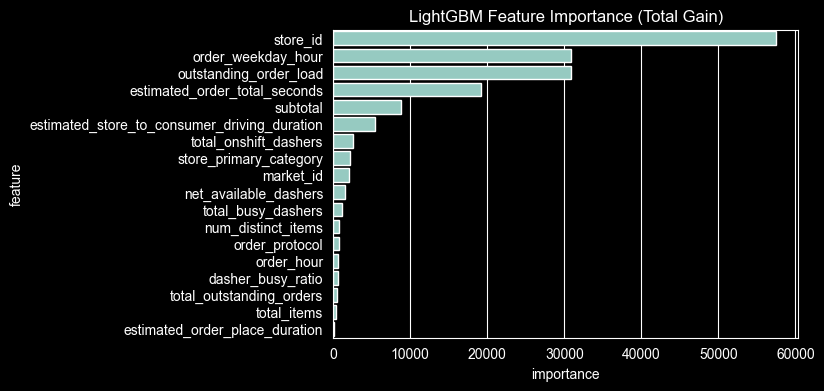

In [129]:
import seaborn as sns

feature_names = lgbm_num_features + lgbm_cat_features
importance_values = lgb_model.feature_importance(importance_type='gain')

lbgm_importance = pd.DataFrame({
                    'feature': feature_names,
                    'importance': importance_values
                    }).sort_values(by='importance', ascending=False)

plt.figure(figsize=(6, 4))
sns.barplot(x='importance', y='feature', data=lbgm_importance)
plt.title('LightGBM Feature Importance (Total Gain)')
plt.show()

#### Prediction

In [130]:
lgb_preds = lgb_model.predict(test_df[lgbm_num_features + lgbm_cat_features])
lgb_preds = np.expm1(lgb_preds)
lgb_mae = mean_absolute_error(np.expm1(y_test), lgb_preds)
print(f"LGBM MAE: {lgb_mae:.2f} seconds")

LGBM MAE: 641.08 seconds


# LGBM Hyperparameter-Tuning

In [131]:
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit
from lightgbm import LGBMRegressor

#### Split Train Test

In [132]:
train_df_v2 = df_lgbm.iloc[:train_size].copy()
test_df_v2 = df_lgbm.iloc[train_size:].copy()

#### Converting categorical columns

In [133]:
cat_cols_to_fix = [
    'market_id',
    'store_id',
    'order_protocol',
    'store_primary_category',
    'order_weekday_hour',
    'order_is_weekend'
]
for col in cat_cols_to_fix:
    train_df_v2[col] = train_df_v2[col].astype('category')
    test_df_v2[col] = test_df_v2[col].astype('category')

Log transform target

In [134]:
train_df_v2[target] = np.log1p(train_df_v2[target])
test_df_v2[target] = np.log1p(test_df_v2[target])

Prepare X,y train test

In [135]:
X_train = train_df_v2[lgbm_num_features + lgbm_cat_features]
y_train = train_df_v2[target]

X_test = test_df_v2[lgbm_num_features + lgbm_cat_features]
y_test = test_df_v2[target]

Creating model

In [136]:
lgbm_model = LGBMRegressor(
    objective='regression',
    boosting_type='gbdt',
    random_state=42,
    verbose=-1
)

Parameter grid for best parameter search

In [137]:
param_grid = {
    'n_estimators': [200, 500, 800, 1000],
    'learning_rate': [0.01, 0.03, 0.05, 0.1],
    'num_leaves': [31, 64, 128, 256],
    'max_depth': [-1, 5, 10, 15],
    'min_child_samples': [20, 50, 100],
    'subsample': [0.7, 0.8, 0.9, 1.0],
    'colsample_bytree': [0.7, 0.8, 0.9, 1.0],
    'reg_alpha': [0.0, 0.1, 0.5, 1.0],
    'reg_lambda': [0.0, 0.1, 0.5, 1.0]
}

Time Series Cross Validation

In [138]:
tscv = TimeSeriesSplit(n_splits=5)

Randomized Search CV

In [139]:
random_search = RandomizedSearchCV(
    estimator=lgbm_model,
    param_distributions=param_grid,
    n_iter=30,
    scoring='neg_mean_absolute_error',
    cv=tscv,
    verbose=2,
    random_state=42,
    n_jobs=-1
)

Fit random search

In [140]:
random_search.fit(
    X_train,
    y_train,
    categorical_feature=lgbm_cat_features
)

Fitting 5 folds for each of 30 candidates, totalling 150 fits
[CV] END colsample_bytree=0.9, learning_rate=0.03, max_depth=15, min_child_samples=100, n_estimators=200, num_leaves=64, reg_alpha=0.5, reg_lambda=0.1, subsample=0.9; total time=   9.2s
[CV] END colsample_bytree=0.9, learning_rate=0.03, max_depth=15, min_child_samples=100, n_estimators=200, num_leaves=64, reg_alpha=0.5, reg_lambda=0.1, subsample=0.9; total time=  10.5s
[CV] END colsample_bytree=0.9, learning_rate=0.03, max_depth=15, min_child_samples=100, n_estimators=200, num_leaves=64, reg_alpha=0.5, reg_lambda=0.1, subsample=0.9; total time=  10.8s
[CV] END colsample_bytree=0.9, learning_rate=0.03, max_depth=15, min_child_samples=100, n_estimators=200, num_leaves=64, reg_alpha=0.5, reg_lambda=0.1, subsample=0.9; total time=  12.1s
[CV] END colsample_bytree=0.9, learning_rate=0.03, max_depth=15, min_child_samples=100, n_estimators=200, num_leaves=64, reg_alpha=0.5, reg_lambda=0.1, subsample=0.9; total time=  13.7s
[CV] END

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","LGBMRegressor...2, verbose=-1)"
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'colsample_bytree': [0.7, 0.8, ...], 'learning_rate': [0.01, 0.03, ...], 'max_depth': [-1, 5, ...], 'min_child_samples': [20, 50, ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",30
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'neg_mean_absolute_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strat

Best Parameters and best CV score

In [141]:
print("\nBest Parameters:")
print(random_search.best_params_)

print("\nBest CV Score (Negative MAE):")
print(random_search.best_score_)


Best Parameters:
{'subsample': 1.0, 'reg_lambda': 0.1, 'reg_alpha': 0.1, 'num_leaves': 128, 'n_estimators': 800, 'min_child_samples': 20, 'max_depth': 5, 'learning_rate': 0.03, 'colsample_bytree': 0.7}

Best CV Score (Negative MAE):
-0.22968384085173438


#### Final model using best parameters

In [142]:
best_lgbm = random_search.best_estimator_

best_lgbm.fit(
    X_train,
    y_train,
    categorical_feature=lgbm_cat_features
)

,boosting_type,'gbdt'
,num_leaves,128
,max_depth,5
,learning_rate,0.03
,n_estimators,800
,subsample_for_bin,200000
,objective,'regression'
,class_weight,None
,min_split_gain,0.0
,min_child_weight,0.001
,min_child_samples,20


#### Prediction on test

In [143]:
lgb_preds_log = best_lgbm.predict(X_test)

Reverse log transformation

In [144]:
lgb_preds = np.expm1(lgb_preds_log)
y_test_actual = np.expm1(y_test)

#### Evaluate model

In [145]:
lgb_mae = mean_absolute_error(y_test_actual, lgb_preds)
print(f"\nFinal LightGBM MAE: {lgb_mae:.2f} seconds")


Final LightGBM MAE: 640.46 seconds


# PHASE 4: Ensemble Models

In [146]:
weight_nn = 0.3
weight_lgb = 0.7

In [147]:
final_prediction = (weight_nn * nn_preds) + (weight_lgb * lgb_preds)

In [148]:
ensemble_mae = mean_absolute_error(np.expm1(y_test), final_prediction)
print(f"Neural Network MAE: {nn_mae:.2f} seconds")
print(f"LGBM MAE: {lgb_mae:.2f} seconds")
print(f"Ensemble MAE: {ensemble_mae:.2f} seconds")

Neural Network MAE: 662.89 seconds
LGBM MAE: 640.46 seconds
Ensemble MAE: 638.77 seconds


## Residual Analysis

In [149]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

In [150]:
residuals = np.expm1(y_test) - final_prediction

In [151]:
res_df = test_df
res_df['actual'] = np.expm1(y_test)
res_df['predicted'] = final_prediction
res_df['residuals'] = residuals
res_df['abs_error_min'] = np.abs(residuals) /60

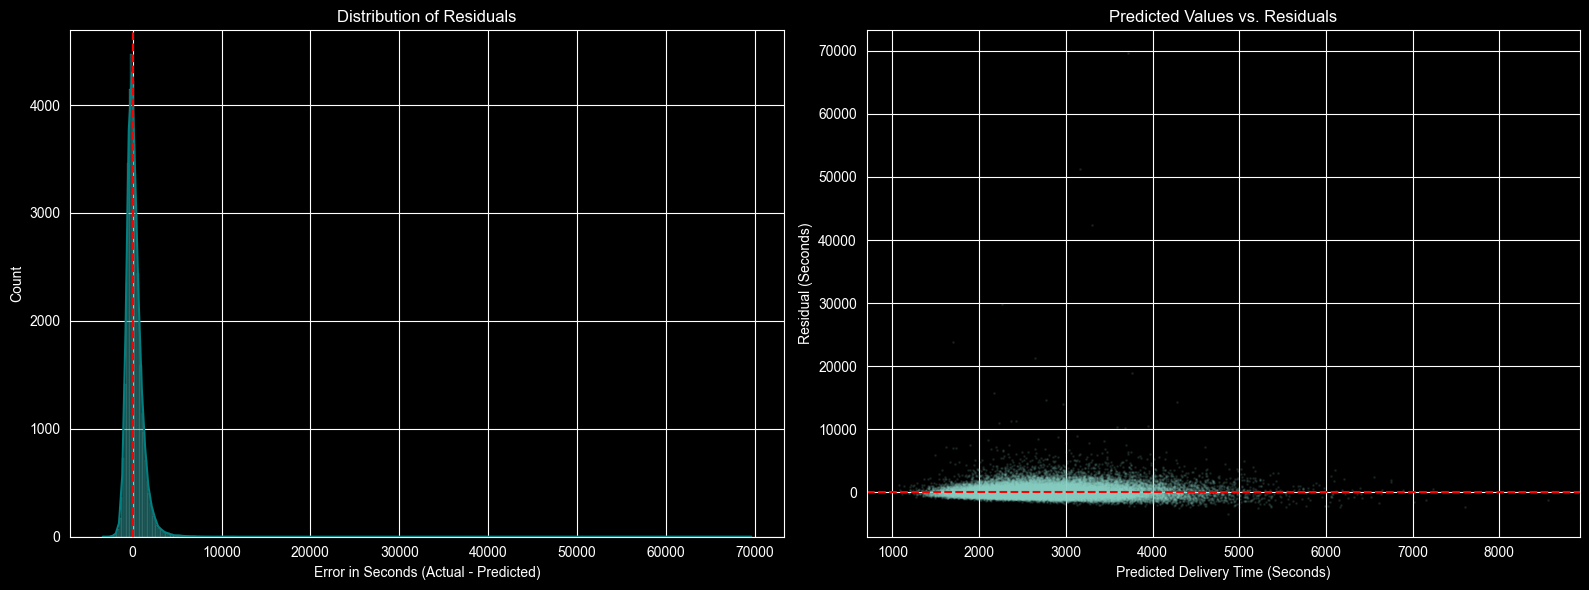

Total Test Samples: 39484
Number of Egregious Delays (>30m error): 1963
Percentage of total: 4.97%

Top 10 Hardest Categories to Predict (Average Error > 30m):
store_primary_category
nepalese             110.277709
southern              74.361047
convenience-store     73.822135
indian                70.686763
tapas                 65.643655
catering              64.287042
spanish               61.148492
mediterranean         57.395583
filipino              56.711023
bubble-tea            56.673228
Name: abs_error_min, dtype: float64


In [152]:
plt.figure(figsize=(16, 6))

plt.subplot(1, 2, 1)
sns.histplot(residuals, kde=True, color='teal')
plt.axvline(0, color='red', linestyle='--')
plt.title('Distribution of Residuals')
plt.xlabel('Error in Seconds (Actual - Predicted)')

plt.subplot(1, 2, 2)
plt.scatter(final_prediction, residuals, alpha=0.1, s=1)
plt.axhline(0, color='red', linestyle='--')
plt.title('Predicted Values vs. Residuals')
plt.xlabel('Predicted Delivery Time (Seconds)')
plt.ylabel('Residual (Seconds)')
plt.tight_layout()
plt.show()

egregious = res_df[res_df['abs_error_min'] > 30]
print(f"Total Test Samples: {len(res_df)}")
print(f"Number of Egregious Delays (>30m error): {len(egregious)}")
print(f"Percentage of total: {100 * len(egregious) / len(res_df):.2f}%")
print("\nTop 10 Hardest Categories to Predict (Average Error > 30m):")
print(egregious.groupby('store_primary_category')['abs_error_min'].mean().sort_values(ascending=False).head(10))